In [5]:
#Import packages used
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

#Load custom module
from os.path import dirname, abspath
d = dirname(abspath(""))
import sys
sys.path.append(d + '\\EOsimSuite')
from EOsimsuite import EOsimsuite as EOsim

In [7]:
def sensFunc(rs,specInd,EOparams):
    v = EOparams['v']
    K = EOparams['K']
    
    return np.squeeze(0.35 * np.array([(rs*v)/(rs+K)]))

def impactFunc(rs,specInd,EOparams):
    v = EOparams['v']
    K = EOparams['K']

    return np.squeeze(-np.array([(rs*v)/(rs+K)]))

150


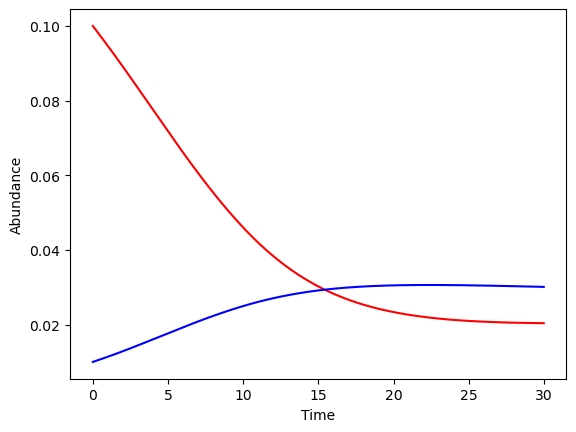

In [11]:
#1 species function test
v = np.array([2.1])
K = np.array([0.3])
EOparams = {'v':v, 'K':K}

rIn = np.array([0.1])
sysParams = {'rIn':rIn}

B0 = np.array([0.01]) #Starting concentration of bacteria in batch (biomass)

thisSim = EOsim(impactFunc,sensFunc,EOparams,sysParams,B0,rIn)
thisSim.set_timeSettings(tSpan = [0,30], dt=0.01)
thisSim.set_dilSettings(D=0.05,transT=0.2)
thisSim.simEOmodel('Chemostat')
thisSim.plotSolutionTimecourse()

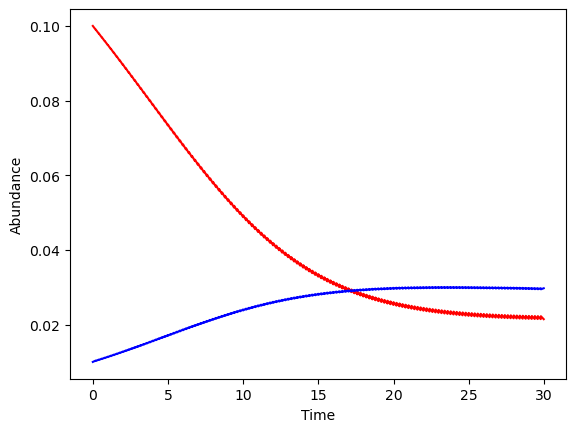

In [13]:
#Demonstrate that high-frequency serial transfers converge on chemostat dynamics 
thisSim.simEOmodel('SerialTransfer')
thisSim.plotSolutionTimecourse()

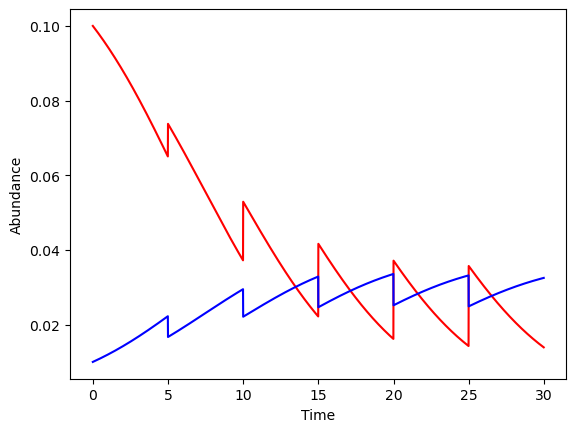

In [15]:
#Repeat serial transfer simulation with much longer transfer times
thisSim.set_dilSettings(D=0.05,transT=5)
thisSim.simEOmodel('SerialTransfer')
thisSim.plotSolutionTimecourse()